In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_parquet(r'..\data\processed\options_long.parquet')

In [3]:
df

,quote_unixtime,quote_readtime,quote_date,quote_time_hours,underlying_last,expire_date,expire_unix,dte,delta,gamma,...,volume,last,bid,ask,strike,strike_distance,strike_distance_pct,size_bid,size_ask,type
0,1630526400,2021-09-01 16:00:00,2021-09-01,16.0,451.85,2021-09-01,1630526400,0.0,1.00000,0.0,...,1.0,182.65,181.09,182.31,270.0,181.9,0.402,1,1,call
1,1630526400,2021-09-01 16:00:00,2021-09-01,16.0,451.85,2021-09-01,1630526400,0.0,1.00000,0.0,...,NaN,0.00,176.09,177.31,275.0,176.9,0.391,1,1,call
2,1630526400,2021-09-01 16:00:00,2021-09-01,16.0,451.85,2021-09-01,1630526400,0.0,1.00000,0.0,...,25.0,157.75,171.09,172.31,280.0,171.9,0.380,1,1,call
3,1630526400,2021-09-01 16:00:00,2021-09-01,16.0,451.85,2021-09-01,1630526400,0.0,1.00000,0.0,...,25.0,153.45,166.14,167.30,285.0,166.9,0.369,1,1,call
4,1630526400,2021-09-01 16:00:00,2021-09-01,16.0,451.85,2021-09-01,1630526400,0.0,1.00000,0.0,...,25.0,147.76,161.09,162.31,290.0,161.9,0.358,1,1,call
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7099613,1614373200,2021-02-26 16:00:00,2021-02-26,16.0,380.36,2023-12-15,1702674000,1022.0,-0.97430,0.0,...,NaN,0.00,196.20,200.50,570.0,189.6,0.499,50,2,put
7099614,1614373200,2021-02-26 16:00:00,2021-02-26,16.0,380.36,2023-12-15,1702674000,1022.0,-0.97337,0.0,...,NaN,0.00,200.92,205.50,575.0,194.6,0.512,200,1,put
7099615,1614373200,2021-02-26 16:00:00,2021-02-26,16.0,380.36,2023-12-15,1702674000,1022.0,-0.97362,0.0,...,NaN,0.00,205.00,210.00,580.0,199.6,0.525,2,1,put
7099616,1614373200,2021-02-26 16:00:00,2021-02-26,16.0,380.36,2023-12-15,1702674000,1022.0,-0.97339,0.0,...,NaN,0.00,209.50,214.50,585.0,204.6,0.538,2,2,put


In [4]:
datacounts = [df.shape[0]]
log = {'Removed' : [], 'Left' : []}
def filter_count(data, datacounts) :
    prev = datacounts[-1]
    removed = prev - data.shape[0]
    new_count = data.shape[0]

    perc_rows_remaining = (data.shape[0]/datacounts[0]) * 100


    # for the distribution of calls and puts
    call_num = data[data['type'] == 'call'].groupby(data['quote_date'])['iv'].count()
    put_num = data[data['type'] == 'put'].groupby(data['quote_date'])['iv'].count()

    total_calls = data[data['type'] == 'call']['iv'].count()
    total_puts = data[data['type'] == 'put']['iv'].count()

    total_days =  data['quote_date'].nunique()


    datacounts.append(data.shape[0])
    log['Removed'].append(removed)
    log['Left'].append(new_count)


    print(f'Number of rows eliminated : {removed}')
    print(f'Number of rows remaining : {new_count}')
    print()
    print(f'Percentage of rows remaining : {perc_rows_remaining : .2f}')
    print()
    print(f'Mean/Min/Max calls per day : {call_num.mean() : .2f} / {call_num.min()} / {call_num.max()}')
    print(f'Mean/Min/Max puts per day : {put_num.mean() : .2f} / {put_num.min()} / {put_num.max()}')
    print()
    print(f'Total number of calls : {total_calls}')
    print(f'Total number of puts : {total_puts}')
    print()
    print(f'Total days : {total_days}')



In [5]:
df.sample(5).T

,2160702,624439,4089868,1319409,2940700
quote_unixtime,1581454800,1588795200,1597176000,1608238800,1635883200
quote_readtime,2020-02-11 16:00:00,2020-05-06 16:00:00,2020-08-11 16:00:00,2020-12-17 16:00:00,2021-11-02 16:00:00
quote_date,2020-02-11 00:00:00,2020-05-06 00:00:00,2020-08-11 00:00:00,2020-12-17 00:00:00,2021-11-02 00:00:00
quote_time_hours,16.0,16.0,16.0,16.0,16.0
underlying_last,335.27,284.37,332.8,372.24,461.87
expire_date,2020-05-15 00:00:00,2021-03-31 00:00:00,2020-10-16 00:00:00,2021-05-21 00:00:00,2021-11-26 00:00:00
expire_unix,1589572800,1617220800,1602878400,1621627200,1637960400
dte,93.96,329.0,66.0,154.96,24.04
delta,0.50135,0.4594,-0.09288,0.66822,0.93854
gamma,0.01713,0.00561,0.00319,0.00661,0.00078


# Filter 1 : Remove NaN IVs

In [6]:
df['iv'].isna().sum()

np.int64(382881)

In [7]:
df = df[~df['iv'].isna()]

In [8]:
df.shape

(6716737, 24)

In [9]:
filter_count(df, datacounts)

Number of rows eliminated : 382881
Number of rows remaining : 6716737

Percentage of rows remaining :  94.61

Mean/Min/Max calls per day :  4456.90 / 3194 / 5855
Mean/Min/Max puts per day :  4510.71 / 2138 / 5816

Total number of calls : 3338217
Total number of puts : 3378520

Total days : 749


# Filter 2 : Remove Non Positive Volume fields

In [10]:
(df['volume'] == 0).sum()

np.int64(1454294)

In [11]:
df['volume'].isna().sum()

np.int64(1260436)

In [12]:
df.shape[0] - (df['volume'] > 0).sum()

np.int64(2714730)

In [13]:
df = df[df['volume'] > 0]

In [14]:
df.shape

(4002007, 24)

In [15]:
filter_count(df, datacounts)

Number of rows eliminated : 2714730
Number of rows remaining : 4002007

Percentage of rows remaining :  56.37

Mean/Min/Max calls per day :  2575.45 / 1033 / 4126
Mean/Min/Max puts per day :  2767.68 / 1199 / 4137

Total number of calls : 1929013
Total number of puts : 2072994

Total days : 749


# Filter 3 : Remove Non positive bids

In [16]:
df.shape[0] - (df['bid'] > 0).sum()

np.int64(176261)

In [17]:
df = df[df['bid'] > 0]

In [18]:
df.shape

(3825746, 24)

In [19]:
filter_count(df, datacounts)

Number of rows eliminated : 176261
Number of rows remaining : 3825746

Percentage of rows remaining :  53.89

Mean/Min/Max calls per day :  2456.20 / 986 / 3862
Mean/Min/Max puts per day :  2651.61 / 1155 / 4093

Total number of calls : 1839692
Total number of puts : 1986054

Total days : 749


# Filter 4 : Keep instances only where ask > bid

In [20]:
(df['bid'] >= df['ask']).sum()

np.int64(57027)

In [21]:
df = df[df['ask'] > df['bid']]

In [22]:
df.shape

(3768719, 24)

In [23]:
filter_count(df, datacounts)

Number of rows eliminated : 57027
Number of rows remaining : 3768719

Percentage of rows remaining :  53.08

Mean/Min/Max calls per day :  2430.30 / 980 / 3862
Mean/Min/Max puts per day :  2601.37 / 1153 / 4075

Total number of calls : 1820291
Total number of puts : 1948428

Total days : 749


# Filter 5 : Keep instances where relative spread is <= 0.5

In [24]:
df['mid'] = (df['bid'] + df['ask'])/2

In [25]:
df['spread'] = df['ask'] - df['bid']

In [26]:
df['relative_spread'] = df['spread']/df['mid']

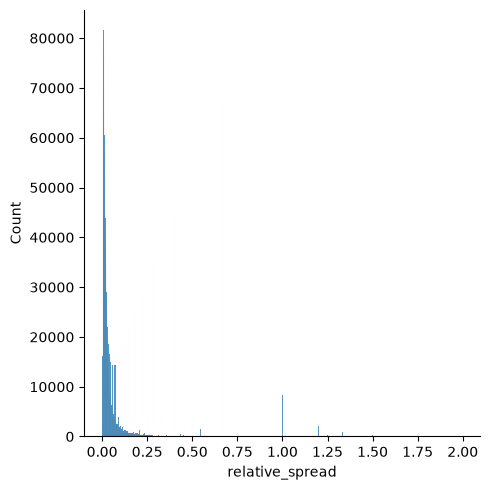

In [27]:
sns.displot(df['relative_spread'])

In [28]:
(df['relative_spread'] <= 0.5).sum()

np.int64(3634144)

In [29]:
df = df[df['relative_spread'] <= 0.5]

In [30]:
df.shape

(3634144, 27)

In [31]:
filter_count(df, datacounts)

Number of rows eliminated : 134575
Number of rows remaining : 3634144

Percentage of rows remaining :  51.19

Mean/Min/Max calls per day :  2316.75 / 952 / 3660
Mean/Min/Max puts per day :  2535.24 / 1134 / 4028

Total number of calls : 1735248
Total number of puts : 1898896

Total days : 749


# Filter 6 : Keep instances where IV is between 1% and 200%

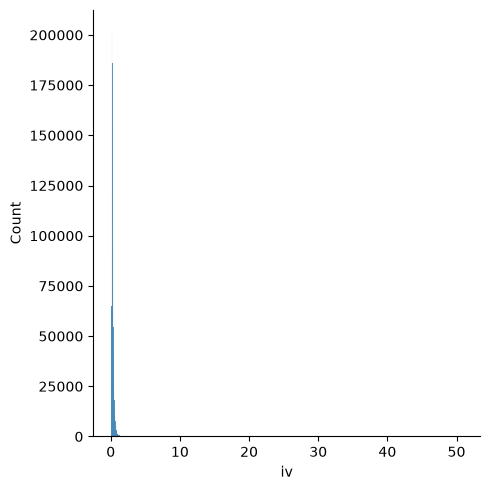

In [32]:
sns.displot(df['iv'])

In [33]:
((df['iv'] <= 2) & (df['iv'] >= 0.01)).sum()

np.int64(3573138)

In [34]:
df = df[((df['iv'] <= 2) & (df['iv'] >= 0.01))]

In [35]:
df.shape

(3573138, 27)

In [36]:
filter_count(df, datacounts)

Number of rows eliminated : 61006
Number of rows remaining : 3573138

Percentage of rows remaining :  50.33

Mean/Min/Max calls per day :  2298.52 / 939 / 3589
Mean/Min/Max puts per day :  2472.02 / 1110 / 3946

Total number of calls : 1721595
Total number of puts : 1851543

Total days : 749


# Filter 7 : Keep instances where dte >= 7

In [37]:
(df['dte'] >= 7).sum()

np.int64(3391881)

In [38]:
df = df[df['dte'] >= 7]

In [39]:
df.shape

(3391881, 27)

In [40]:
filter_count(df, datacounts)

Number of rows eliminated : 181257
Number of rows remaining : 3391881

Percentage of rows remaining :  47.78

Mean/Min/Max calls per day :  2182.08 / 845 / 3426
Mean/Min/Max puts per day :  2346.47 / 995 / 3669

Total number of calls : 1634377
Total number of puts : 1757504

Total days : 749


In [41]:
log

{'Removed': [382881, 2714730, 176261, 57027, 134575, 61006, 181257],
 'Left': [6716737, 4002007, 3825746, 3768719, 3634144, 3573138, 3391881]}

In [42]:
pd.DataFrame(log)

,Removed,Left
0,382881,6716737
1,2714730,4002007
2,176261,3825746
3,57027,3768719
4,134575,3634144
5,61006,3573138
6,181257,3391881


In [43]:
df.to_parquet(r'..\data\processed\options_filtered.parquet')

Which filter removes the most rows, and why do you think so?
(Look at your log: one filter is far bigger than the rest.)

Does the order of the filters change the final result? Does it change the log?
(Two separate questions: think about the final rows, then about the “removed” counts per step.)

What fraction of the data was very short-dated (DTE < 7)? Is it worth keeping as a separate group for later?
(Your log tells you how many the DTE filter removed. Think about weekly options and what makes them hard to model.)

Why do more puts than calls survive the filters?
(Think about which options investors buy as protection against a market crash, and how that affects trading volume.)